In [ ]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor, IsolationForest
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt

In [ ]:
drugs = pd.DataFrame({
    "drug_id":["D01","D02","D03","D04","D05","D06","D07","D08","D09","D10","D11","D12","D13","D14","D15","D16","D17","D18","D19"],
    "baseline_demand":[320,90,210,240,180,70,130,450,300,40,260,170,200,85,55,75,140,190,230],
    "shelf_life":[104,52,104,104,104,78,104,104,78,52,78,78,104,78,52,78,78,104,78],
    "seasonal_amplitude":[0.05,0.05,0.04,0.04,0.04,0.03,0.03,0.25,0.30,0.20,0.15,0.12,0.25,0.30,0.35,0.30,0.25,0.10,0.30]
})

drugs.head()

,drug_id,baseline_demand,shelf_life,seasonal_amplitude
0,D01,320,104,0.05
1,D02,90,52,0.05
2,D03,210,104,0.04
3,D04,240,104,0.04
4,D05,180,104,0.04


In [ ]:
np.random.seed(42)

drugs["weekly_demand"] = (
    drugs["baseline_demand"] *
    (1 + np.random.uniform(-0.15,0.15,len(drugs)))
)

drugs.head()

,drug_id,baseline_demand,shelf_life,seasonal_amplitude,weekly_demand
0,D01,320,104,0.05,307.955851
1,D02,90,52,0.05,102.169286
2,D03,210,104,0.04,224.615618
3,D04,240,104,0.04,247.103411
4,D05,180,104,0.04,161.425007


In [ ]:
X = drugs[
    ["baseline_demand", "shelf_life", "seasonal_amplitude"]
]

y = drugs["weekly_demand"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

forecast_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

forecast_model.fit(X_train, y_train)

print("Forecast model trained successfully")

Forecast model trained successfully


In [ ]:
predictions = forecast_model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)

print("MAE:", mae)


MAE: 21.712337952436975


In [ ]:
iso = IsolationForest(
    contamination=0.1,
    random_state=42
)

drugs["anomaly"] = iso.fit_predict(
    drugs[["weekly_demand"]]
)

drugs[["drug_id","weekly_demand","anomaly"]]

,drug_id,weekly_demand,anomaly
0,D01,307.955851,1
1,D02,102.169286,1
2,D03,224.615618,1
3,D04,247.103411,1
4,D05,161.425007,1
5,D06,62.775885,1
6,D07,112.765261,1
7,D08,499.433780,-1
8,D09,309.100351,1
9,D10,42.496871,-1


In [ ]:
anomalies = drugs[drugs["anomaly"] == -1]

anomalies

,drug_id,baseline_demand,shelf_life,seasonal_amplitude,weekly_demand,anomaly
7,D08,450,104,0.25,499.433780,-1
9,D10,40,52,0.20,42.496871,-1


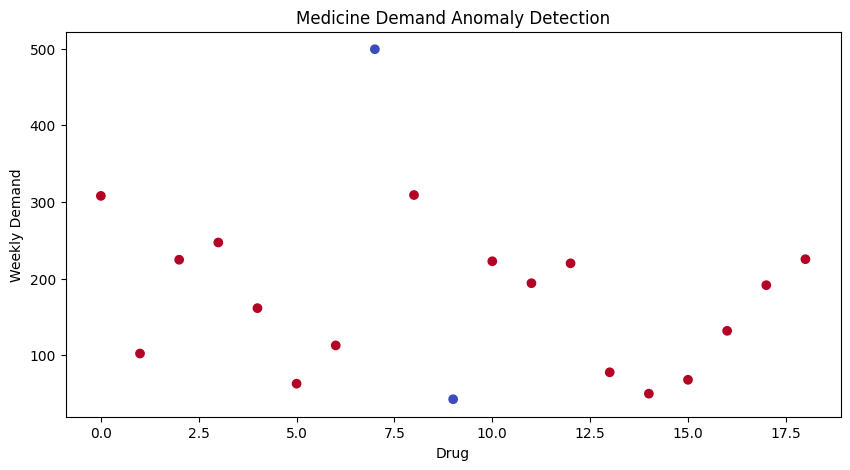

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.scatter(
    drugs.index,
    drugs["weekly_demand"],
    c=drugs["anomaly"],
    cmap="coolwarm"
)

plt.title("Medicine Demand Anomaly Detection")
plt.xlabel("Drug")
plt.ylabel("Weekly Demand")

plt.show()

In [ ]:
print("Total Records:", len(drugs))

print("Total Anomalies:", len(drugs[drugs["anomaly"] == -1]))

Total Records: 19
Total Anomalies: 2


In [ ]:
drugs[drugs["anomaly"] == -1]

,drug_id,baseline_demand,shelf_life,seasonal_amplitude,weekly_demand,anomaly
7,D08,450,104,0.25,499.433780,-1
9,D10,40,52,0.20,42.496871,-1


In [ ]:
weeks = range(1, 53)

records = []

for _, drug in drugs.iterrows():

    for week in weeks:

        seasonal_factor = 1 + (
            drug["seasonal_amplitude"]
            * np.sin(2 * np.pi * week / 52)
        )

        noise = np.random.normal(0, 0.05)

        demand = (
            drug["baseline_demand"]
            * seasonal_factor
            * (1 + noise)
        )

        records.append([
            drug["drug_id"],
            week,
            round(demand)
        ])

history = pd.DataFrame(
    records,
    columns=[
        "drug_id",
        "week",
        "weekly_demand"
    ]
)

history.head()

,drug_id,week,weekly_demand
0,D01,1,335
1,D01,2,299
2,D01,3,319
3,D01,4,315
4,D01,5,318


In [ ]:
X = history[["week"]]

y = history["weekly_demand"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

forecast_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

forecast_model.fit(X_train, y_train)

predictions = forecast_model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)

print("MAE =", mae)

MAE = 79.22002393546589


In [ ]:
future_weeks = pd.DataFrame({
    "week":[53,54,55,56]
})

forecast = forecast_model.predict(
    future_weeks
)

print(forecast)

[188.80246244 188.80246244 188.80246244 188.80246244]


In [ ]:
iso = IsolationForest(
    contamination=0.05,
    random_state=42
)

history["anomaly"] = iso.fit_predict(
    history[["weekly_demand"]]
)

history.head()

,drug_id,week,weekly_demand,anomaly
0,D01,1,335,1
1,D01,2,299,1
2,D01,3,319,1
3,D01,4,315,1
4,D01,5,318,1


In [ ]:
history[
    history["anomaly"] == -1
]

,drug_id,week,weekly_demand,anomaly
364,D08,1,481,-1
365,D08,2,512,-1
366,D08,3,507,-1
367,D08,4,499,-1
368,D08,5,512,-1
369,D08,6,517,-1
370,D08,7,542,-1
371,D08,8,513,-1
372,D08,9,559,-1
373,D08,10,553,-1


In [ ]:
history.to_csv(
    "medicine_demand_history.csv",
    index=False
)

print("Dataset saved")

Dataset saved
